# Feature Selection & Dimensionality Reduction: Visium HD (16-µm Binned)

## Introduction

Having filtered technical dropouts and standardized bin depth via out-of-memory size-factor log-normalization in [notebook 08](./08-normalization_VisiumHD_binned.ipynb), we now perform **feature selection** and **dimensionality reduction** on the 16-µm binned `SpatialExperiment` (`spe`) dataset (18,027 genes × 21,278 bins).

While we follow the same analytical progression established for segmented single cells in [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb)—modeling Highly Variable Genes (HVGs), benchmarking Spatially Variable Genes (SVGs), and comparing unconstrained PCA against spatially-aware BANKSY and UMAP embeddings—transitioning from variable-area cell polygons to a fixed 16 × 16 µm (256 µm²) capture lattice introduces _four fundamental statistical and biological shifts_:

1. **Partial-Volume Mixing & Variance Compression:** Each 16-µm bin pools mRNA from ≈ 1–3 adjacent cells and extracellular borders. As observed in [notebook 08](./08-normalization_VisiumHD_binned.ipynb), this geometric averaging compresses upper-bound size factors (max 8.9815 → 3.9354) and shifts the median closer to unity (0.7598 → 0.8662). Consequently, excess biological variance ($\sigma^2_{\text{bio}}$) for cell-type-specific bursts is dampened, and boundary bins spanning epithelial–stromal interfaces occupy intermediate mixtures along the edges of the PC1 × PC2 simplex rather than crisp single-cell vertices.
2. **Uniform Lattice Topology vs. Density-Dependent Cell Graphs:** In segmented space, a fixed $k$-nearest-neighbor graph spans narrow physical radii (≈ 10–25 µm) in packed tumor sheets and wider radii in sparse stroma. On the 16-µm grid, $k$-NN edges sample an almost isotropic lattice footprint everywhere (except along QC-filtered tears and margins).
3. **Double Spatial Smoothing in BANKSY:** Because 16-µm binning already acts as a physical 256 µm² spatial pooling window, applying BANKSY with high neighborhood mixing (λ = 0.8) compounds two layers of smoothing—sharpening macro-anatomical domains (normal mucosa, invasive adenocarcinoma, reactive submucosa) while further diluting rare single-cell niches.
4. **Coordinate Scale & Out-of-Memory Execution:** Spatial coordinates in `spe` (`pxl_col_in_fullres`, `pxl_row_in_fullres`) are stored in full-resolution pixels rather than physical microns, shifting raw distance-scaled `nnSVG` inverse length-scales ($\phi = 1/l_g$) while leaving rank-based `LR_stat`, `prop_sv`, and $k$-NN methods (`Moran's I`, `BANKSY`) invariant. All primary assays remain HDF5-backed `DelayedMatrix` objects, avoiding full-matrix RAM realization.

## Learning objectives

* Model gene-level mean-variance relationships out-of-memory on HDF5-backed `DelayedMatrix` `logcounts` via `scran::modelGeneVarByPoisson()` and compare HVG dispersion against segmented single cells.
* Construct a lattice $k$-NN spatial weight graph directly from `spatialCoords(spe)` via `spdep` to compute Moran's $I$, and benchmark it against multi-scale Gaussian Process modeling (`nnSVG`).
* Compute unconstrained standard PCA (`scater::runPCA`) and spatially-aware BANKSY PCA (`Banksy::computeBanksy`, `Banksy::runBanksyPCA`), contrasting how grid-level partial-volume mixing reshapes component loadings and scree curves.
* Project molecular and spatio-molecular components onto tissue coordinates with `ggspavis::plotCoords()` and onto 2D UMAP manifolds (`scater::runUMAP`).

## Environment setup

### Loading libraries

We load the pure `SpatialExperiment` + `HDF5Array` + `ggspavis` stack alongside `spdep` for lattice spatial autocorrelation, `scran`/`scater` for variance modeling and dimensionality reduction, and `Banksy` for spatio-molecular augmentation.

In [1]:
suppressPackageStartupMessages(suppressWarnings({
  # Core spatial container & out-of-memory HDF5 backend
  library(SpatialExperiment)
  library(HDF5Array)

  # Single-cell statistics & feature modeling
  library(scran)
  library(scater)

  # Spatial neighbor graphs, autocorrelation & SVGs
  library(spdep)
  library(nnSVG)

  # Spatially-aware dimensionality reduction
  library(Banksy)

  # Visualization, palettes & layouts
  library(ggspavis)
  library(ggplot2)
  library(patchwork)
  library(pals)
}))

# Enforce global reproducibility for stochastic algorithms (PCA, UMAP, sampling)
set.seed(42)

### Restoring the normalized Visium HD dataset

We restore the normalized 16-µm binned `SpatialExperiment` (`spe`) object exported at the end of [notebook 08](./08-normalization_VisiumHD_binned.ipynb) and verify that both `counts` and `logcounts` remain out-of-memory `DelayedMatrix` assays.

In [2]:
# Define path to the normalized Visium HD 16-µm binned object from notebook 08
spe_path <- "output/spe_visiumhd_binned_normalized"

# Restore the SpatialExperiment object with its HDF5-backed DelayedMatrix assays
spe <- loadHDF5SummarizedExperiment(dir = spe_path)

# Verify container architecture, assays, and spatial coordinate names
spe


class: SpatialExperiment 
dim: 18027 21278 
metadata(2): resouces spatialList
assays(2): counts logcounts
rownames(18027): SAMD11 NOC2L ... MT-ND6 MT-CYB
rowData names(4): ID Symbol Type subsets_Mito
colnames(21278): s_016um_00144_00175-1 s_016um_00204_00145-1 ...
  s_016um_00231_00291-1 s_016um_00193_00227-1
colData names(35): barcode in_tissue ... CEACAM5_raw CEACAM5_lognorm
reducedDimNames(0):
mainExpName: Gene Expression
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

In [3]:
is(counts(spe), "DelayedMatrix")
is(logcounts(spe), "DelayedMatrix")

[1] TRUE

[1] TRUE

This object contains 21,278 post-QC 16-µm bins and 18,027 expressed genes, with `counts` and `logcounts` backed on disk and `spatialCoords(spe)` storing full-resolution pixel coordinates (`pxl_col_in_fullres`, `pxl_row_in_fullres`). Note that `reducedDimNames(spe)` is currently empty (`0`), as [notebook 05](./05-quality_control_VisiumHD_binned.ipynb) did not attach a `PCA_artifacts` slot.

## Feature selection

### Highly Variable Genes (HVGs)

#### Modeling the Mean-Variance Relationship

We apply `scran::modelGeneVarByPoisson()` directly to the `DelayedMatrix` `logcounts` assay. Through delayed block processing, `scran` computes per-gene mean and total variance without loading the dense `18,027 × 21,278` matrix into memory, decomposing observed variance into a fitted Poisson technical trend ($\sigma^2_{\text{tech}}$) and excess biological variance ($\sigma^2_{\text{bio}}$).

In [4]:
# Model mean-variance relationship under a Poisson technical noise assumption (out-of-memory)
gene_var <- modelGeneVarByPoisson(spe, assay.type = "logcounts")

Warning message in .model_gene_var_by_poisson(assay(x, i = assay.type), ...):
"'modelGeneCV2ByPoisson' est obsolète.
Voir help("Deprecated")"
Warning message in fitTrendVar(fm, fv, ...):
"'fitTrendVar' est obsolète.
Utilisez plutôt ‘scrapper::fitVarianceTrend’.
Voir help("Deprecated")"
Warning message in combineBlocks(collected, method = method, equiweight = equiweight, :
"'combineBlocks' est obsolète.
Voir help("Deprecated")"


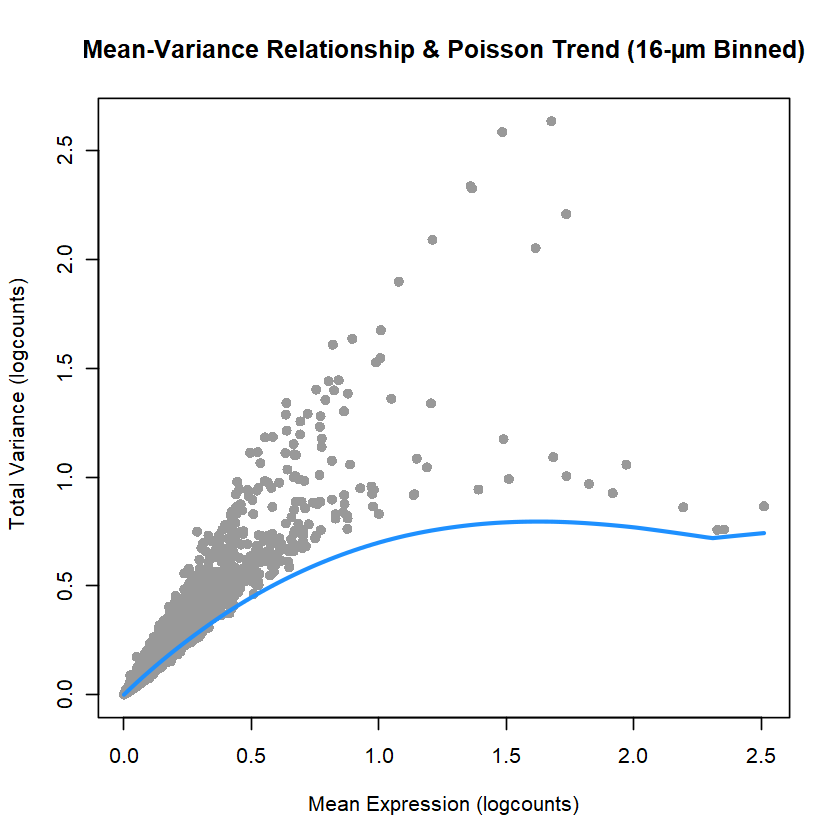

In [5]:
# Scatter plot: Total observed variance vs. mean logcounts across all 18,027 genes
plot(
  x = gene_var[["mean"]],
  y = gene_var[["total"]],
  pch = 16,
  col = "gray60",
  xlab = "Mean Expression (logcounts)",
  ylab = "Total Variance (logcounts)",
  main = "Mean-Variance Relationship & Poisson Trend (16-µm Binned)"
)

# Overlay fitted technical trend stored in metadata(gene_var)[["trend"]]
curve(
  metadata(gene_var)[["trend"]](x),
  add = TRUE,
  col = "dodgerblue",
  lwd = 2.5
)

At first glance, the 16-µm binned mean-variance scatter closely mirrors the segmented single-cell distribution from [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb): the fitted Poisson technical curve plateaus just below 0.8 (compared with 0.57–0.85 in segmented cells), the low-expression baseline tracks the theoretical curve along the same trajectory, and the leading biological outlier still reaches a total variance of ≈ 2.63 (versus 2.756 for `IGKC` in segmented cells). This structural invariance arises for two complementary reasons.

Mathematically, size-factor centering ($\text{mean}(s_i) = 1$) places `logcounts` onto the same [0, 2.5] mean-expression scale with comparable bulk size-factor dispersion across both representations, so the `log1p`-transformed Poisson baseline remains virtually unchanged. Biologically, the dominant drivers of tissue-wide variance—plasma-cell infiltrates, broad desmoplastic collagen bands, and colonic epithelial crypts—form cohesive multi-cell compartments spanning tens to hundreds of microns, well above our 16 µm (256 µm²) capture grid. Consequently, most bins lying inside these macro-compartments retain nearly full biological contrast, with 16-µm grid averaging producing only a modest compression at the upper tail (total > 2.0) where boundary bins mix adjacent cell types.

#### Ranking Top Biological Drivers

We extract the top 10 genes ranked by excess biological variance (`bio`) to examine whether the leading CRC lineage drivers from [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb) (`IGKC`, `COL3A1`, `IGHG1`, `COL1A1`, `VIM`, `JCHAIN`) persist after grid pooling and how their $\sigma^2_{\text{bio}}$ magnitudes compare against single-cell values.

In [6]:
# Sort and inspect top 10 biological variance drivers
gene_var |>
  as.data.frame() |>
  dplyr::slice_max(bio, n = 10)

,mean,total,tech,bio,p.value,FDR
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
COL3A1,1.6769857,2.635416,0.7951685,1.8402480,0,0
COL1A1,1.4840234,2.586287,0.7912445,1.7950422,0,0
COL1A2,1.3597232,2.337451,0.7796183,1.5578323,0,0
SPARC,1.3654862,2.327143,0.7803729,1.5467704,0,0
IGKC,1.7349932,2.209084,0.7930767,1.4160072,0,0
TAGLN,1.2103013,2.091398,0.7552329,1.3361651,0,0
VIM,1.6148728,2.052380,0.7955553,1.2568249,0,0
MMP2,1.0782142,1.898217,0.7232689,1.1749480,0,0
IGHG1,0.8195721,1.608553,0.6278652,0.9806879,0,0


Beneath the nearly identical global scatter envelope, ranking the top 10 biological drivers uncovers a striking **compartmental rank reversal** between segmented cells and 16-µm bins. Whereas single-cell segmentation in [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb) placed the plasma-cell immunoglobulin `IGKC` firmly at the top ($\sigma^2_{\text{bio}} = 1.906$, followed by `COL3A1` at 1.119 and `IGHG1` at 1.096), the 16-µm lattice elevates **desmoplastic extracellular matrix (ECM) and myofibroblast genes** into the top four positions (`COL3A1` = 1.840, `COL1A1` = 1.795, `COL1A2` = 1.558, `SPARC` = 1.547) and brings `MMP2` (1.175) and `LUM` (0.975) into the top 10 alongside `TAGLN` (1.336) and `VIM` (1.257). Concurrently, discrete immune transcripts decline in variance (`IGKC` drops from 1.906 to 1.416 at rank 5; `IGHG1` drops from 1.096 to 0.981 at rank 9), displacing `JCHAIN` and `CD74` from the top 10.

This divergence reflects how tissue morphology interacts with each spatial representation. On one hand, `IGKC`-producing plasma cells are compact (≈ 8–12 µm) lymphocytes packed into narrow lamina propria strips between epithelial crypts; StarDist nuclear segmentation isolates each plasma cell as an extreme, undiluted transcriptional factory, whereas a 16 µm (256 µm²) grid square frequently _mixes_ a plasma cell with adjacent crypt epithelium or stroma, dampening peak immunoglobulin contrast. On the other hand, cancer-associated fibroblasts (CAFs) and smooth-muscle cells within the desmoplastic stroma and submucosa exhibit elongated spindle morphologies with abundant cytoplasmic processes and matrix-associated mRNAs (`COL3A1`, `COL1A1`, `COL1A2`, `SPARC`, `TAGLN`, `LUM`) extending far beyond compact nuclear masks. Unlike nuclear-anchored cell expansion, the continuous 16-µm lattice samples the entire stromal bed uniformly—raising mean normalized expression across these ECM genes (for example, `COL3A1` from 1.127 to 1.677 and `SPARC` from 0.776 to 1.365) and sharpening the tissue-wide dichotomy between continuous stromal territories and epithelial glands.

#### Spatial Topographies of the Top 6 HVGs

As in [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb), we exclude mitochondrial transcripts (`subsets_Mito`) before selecting the top 6 HVGs and mapping their normalized `logcounts` across the 16-µm lattice using `ggspavis::plotCoords()`. Because `plotCoords()` renders points rather than `sf` polygons, color scales map to the `colour` aesthetic (`scale_color_gradientn()`), and `y_reverse = TRUE` (the default) preserves anatomical H&E orientation.

In [7]:
# Exclude mitochondrial transcripts so metabolic noise does not dominate feature selection
is_mito <- rowData(spe)[["subsets_Mito"]]
gene_var_filtered <- gene_var[!is_mito, ]

# Extract top 6 non-mitochondrial HVGs
top_hvg <- getTopHVGs(gene_var_filtered, n = 6)
top_hvg

Warning message in getTopHVGs(gene_var_filtered, n = 6):
"'getTopHVGs' est obsolète.
Utilisez plutôt ‘scrapper::chooseHighlyVariableGenes’.
Voir help("Deprecated")"


[1] "COL3A1" "COL1A1" "COL1A2" "SPARC"  "IGKC"   "TAGLN"

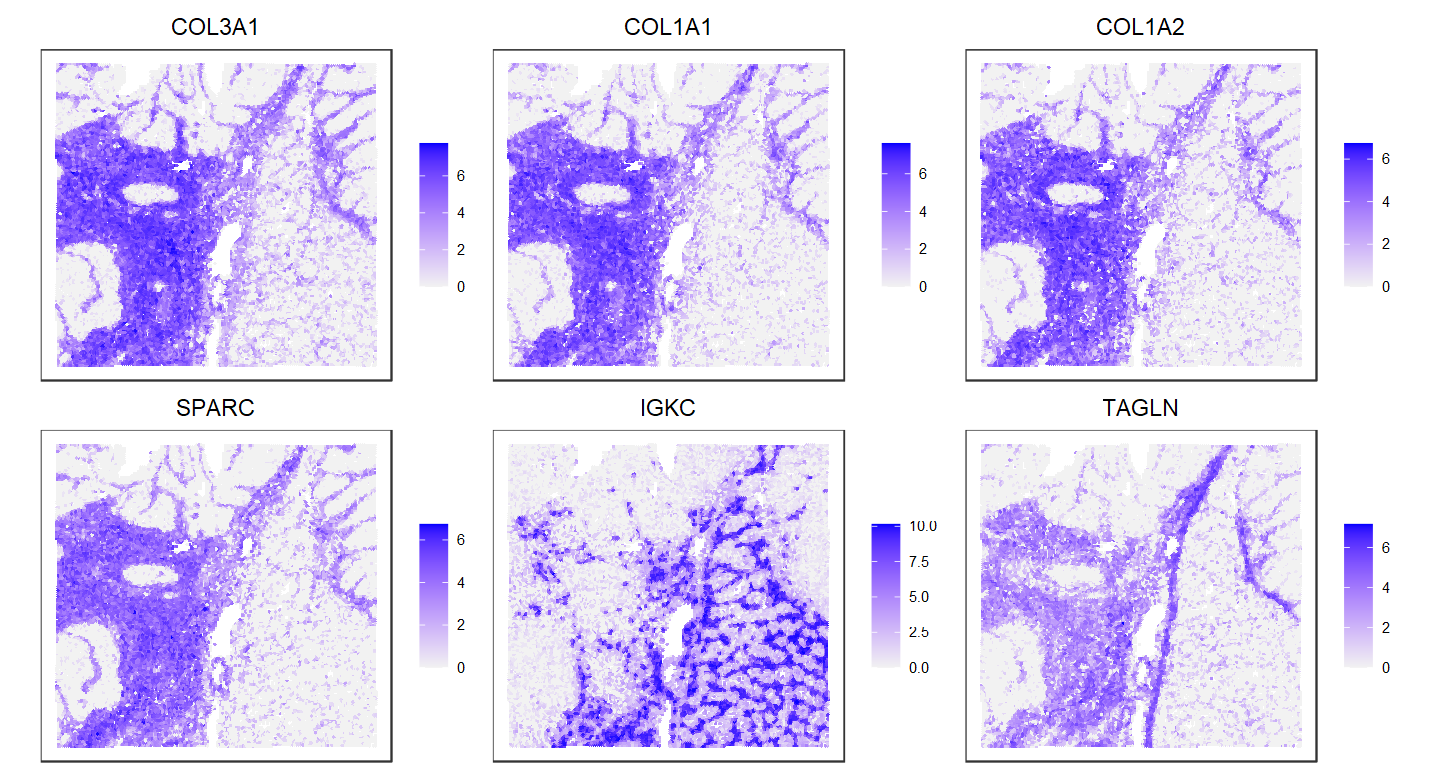

In [8]:
# Render spatial expression topographies across 16-µm bins using ggspavis::plotCoords()
options(repr.plot.width = 12, repr.plot.height = 6.5)

p_top_hvg <- lapply(top_hvg, function(gene) {
  plotCoords(
    spe, 
    annotate = gene, 
    assay_name = "logcounts", 
    point_size = 0.35
  ) +
    # scale_color_gradientn(colors = jet(), name = "logcounts") +
    labs(title = gene)
})

# patchwork
wrap_plots(p_top_hvg, ncol = 3)

Projecting the top six non-mitochondrial HVGs (`COL3A1`, `COL1A1`, `COL1A2`, `SPARC`, `IGKC`, and `TAGLN`) onto the 16-µm lattice confirms that the rank reversal observed above reflects coherent macroscopic tissue architecture rather than technical noise. Four ECM drivers—`COL3A1`, `COL1A1`, `COL1A2`, and `SPARC`—delineate the continuous desmoplastic stroma and submucosal connective tissue across the left and lower compartments, leaving the invasive adenocarcinoma glands as sharp, unstained negative silhouettes. Flanking these broad collagen beds, `TAGLN` (transgelin) sharply highlights the diagonal smooth-muscle ribbon of the **muscularis mucosae** dividing the normal mucosa on the right from the invasive submucosa on the left, alongside stromal myofibroblasts and vascular walls. Meanwhile, `IGKC` recovers the familiar honeycomb lattice of plasma-cell-rich lamina propria encircling normal colonic crypts on the right together with focal immune aggregates along the invasive margin. Compared with the StarDist cell-polygon maps in [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb), these compartments appear visibly softer at their interfaces: both 16 µm (256 µm²) partial-volume averaging across narrow epithelial–lamina propria boundaries and point-based grid rendering (`plotCoords()`) smooth away single-cell edges while preserving tissue-scale anatomical boundaries.

#### Selecting & Summarizing the Top 1,000 HVG Cohort

We select the top 1,000 non-mitochondrial HVGs via `scran::getTopHVGs()`, register `bio` and the `is_hvg` logical mask in `rowData(spe)`, and visualize the heavy-tailed distribution of biological variance across the selected cohort.

In [9]:
# Select the top 1,000 non-mitochondrial HVGs
hvg_1000 <- getTopHVGs(gene_var_filtered, n = 1000)

# Register variance component and selection mask directly in rowData(spe)
rowData(spe)[["bio"]] <- gene_var[["bio"]]
rowData(spe)[["is_hvg"]] <- rownames(spe) %in% hvg_1000

# Verify counts
table(Retained_HVG = rowData(spe)[["is_hvg"]])

Warning message in getTopHVGs(gene_var_filtered, n = 1000):
"'getTopHVGs' est obsolète.
Utilisez plutôt ‘scrapper::chooseHighlyVariableGenes’.
Voir help("Deprecated")"


Retained_HVG
FALSE  TRUE 
17027  1000 

In [10]:
# Summarize biological variance directly across the selected HVGs in rowData
summary(rowData(spe)[rowData(spe)[["is_hvg"]], "bio"])

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
0.08270 0.09872 0.12823 0.18314 0.18673 1.84025 

In [11]:
# Prepare data frame for boxplot + jittered distribution of the 1,000 HVGs
df_hvg_bio <- as.data.frame(rowData(spe)[rowData(spe)[["is_hvg"]], ])
df_hvg_bio[["gene"]] <- rownames(df_hvg_bio)

top_outliers <- df_hvg_bio[order(df_hvg_bio[["bio"]], decreasing = TRUE), ][1:3, ]

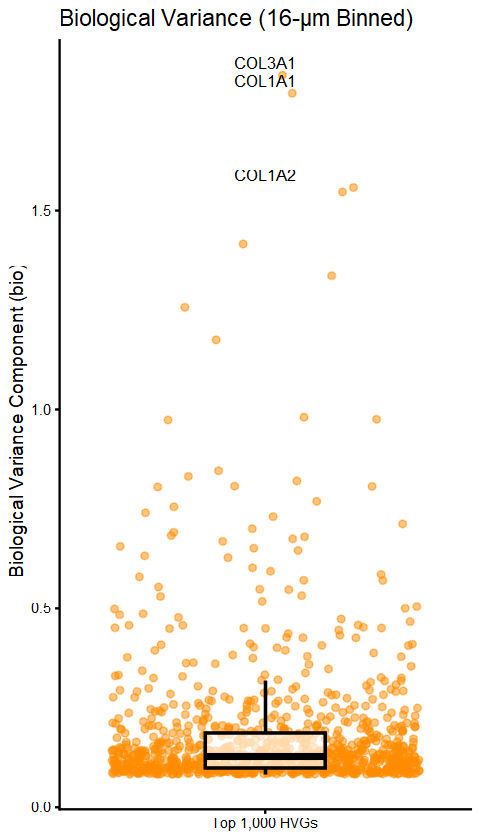

In [12]:
options(repr.plot.width = 4, repr.plot.height = 7)

ggplot(df_hvg_bio, aes(x = "Top 1,000 HVGs", y = bio)) +
  geom_jitter(
    width = 0.45, 
    size = 1.5, 
    alpha = 0.5, 
    color = "darkorange") +
  geom_boxplot(
    width = 0.35, 
    fill = "white", 
    alpha = 0.65, 
    color = "black", 
    linewidth = 0.75, 
    outlier.shape = NA) +
  geom_text(
    data = top_outliers, 
    aes(label = gene), 
    size = 3.5, 
    vjust = -0.5) +
  theme_classic() +
  labs(
    title = "Biological Variance (16-µm Binned)",
    x = NULL,
    y = "Biological Variance Component (bio)"
  )

Although the distribution preserves the same strongly right-skewed silhouette seen in [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb), comparing the five-number summaries uncovers a systematic upward shift across the bulk of the 1,000-HVG cohort. Whereas segmented single cells clustered tightly between a 1st quartile of 0.0608 and a 3rd quartile of 0.1055 (median 0.0762, mean 0.1056), the 16-µm binned cohort spans an interquartile range from 0.0987 to 0.1867 (median 0.1282, mean 0.1831), representing an ≈ 62–77% increase in excess biological variance across ranks 4–1,000. Only the extreme upper ceiling edges slightly downward (1.9061 → 1.8403), accompanied by the replacement of `IGKC` with the fibrillar collagen triad (`COL3A1`, `COL1A1`, `COL1A2`) at the apex of the tail.

Mechanistically, pooling transcripts across uniform 256 µm² capture squares increases UMI depth per observation, reduces zero-inflation in moderately expressed compartment genes, and continuously samples cytoplasmic and extracellular stromal territories—allowing hundreds of genuine tissue-compartment markers to rise further above the Poisson technical noise floor.

### Spatially Variable Genes (SVGs)

To demonstrate that high total variance does not guarantee spatial coherence—even on a 16-µm grid—we sample 6 genes from `hvg_1000` and inspect their spatial distributions before building our 10-gene SVG benchmark panel.

In [13]:
# Sample 6 genes from the 1,000-HVG cohort
set.seed(42)
random_hvg <- sample(hvg_1000, size = 6)
random_hvg

[1] "COPZ2"   "PHF10"   "PLEKHO1" "PEA15"   "PALLD"   "CLU"

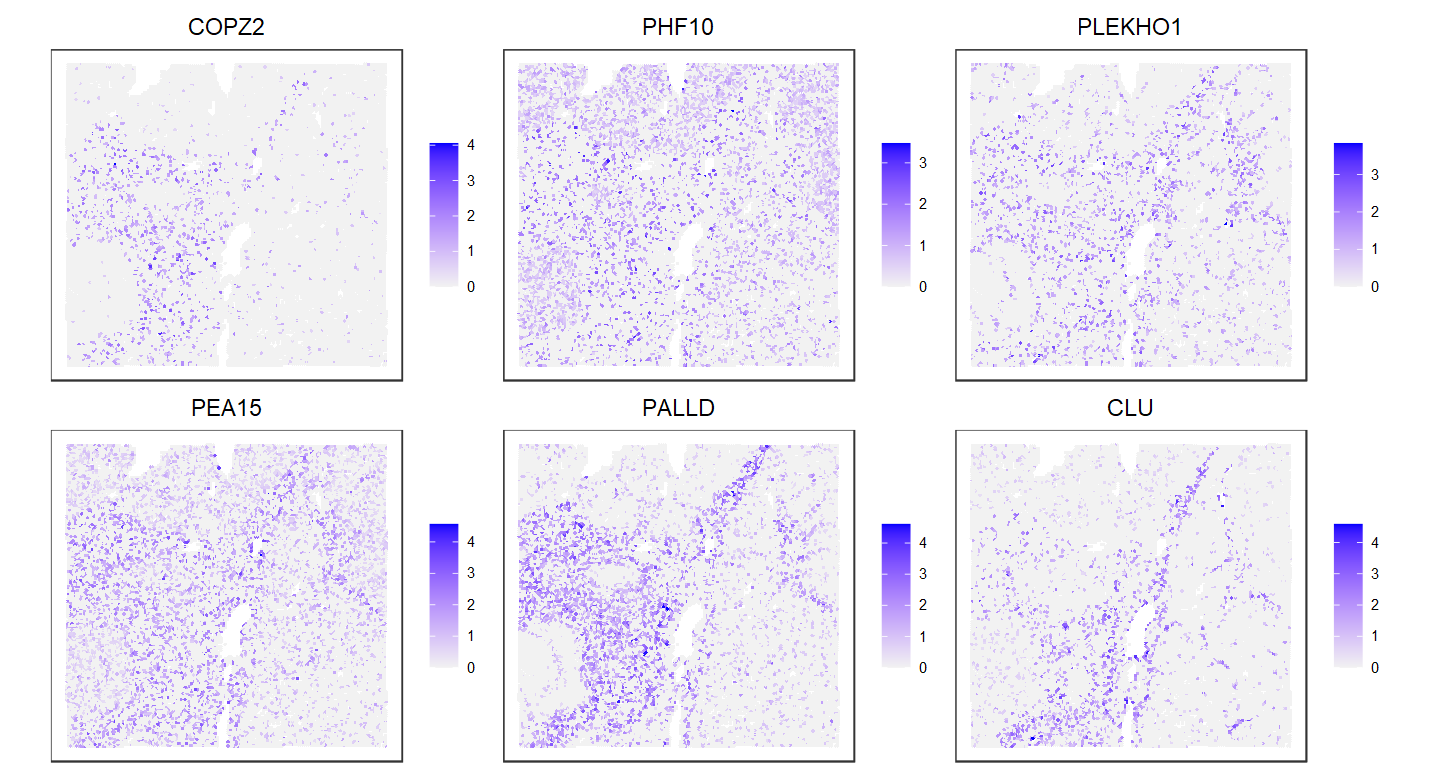

In [14]:
# Map the 6 sampled HVGs across the 16-µm lattice
options(repr.plot.width = 12, repr.plot.height = 6.5)

p_rand_hvg <- lapply(random_hvg, function(gene) {
  plotCoords(
    spe,
    annotate = gene,
    assay_name = "logcounts",
    point_size = 0.35
  ) +
    labs(title = gene)
})

wrap_plots(p_rand_hvg, ncol = 3)

Just as in [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb), our unbiased `set.seed(42)` draw of six features from the top 1,000 HVGs splits cleanly across distinct spatial regimes despite sharing elevated non-spatial biological variance. At one extreme, `PALLD` (palladin) resolves coherent macro-architecture across the desmoplastic stroma and the diagonal muscularis mucosae while remaining absent from epithelial crypts and tumor glands, and `CLU` sharply traces the muscularis mucosae interface alongside focal submucosal clusters. In an intermediate regime, `COPZ2` and `PLEKHO1` exhibit sparse, patchy stromal and immune enrichment. At the opposite extreme, `PHF10` and `PEA15` display widespread "salt-and-pepper" dispersion across epithelial, tumor, and stromal compartments alike—demonstrating that even in 16-µm binned space, high excess biological variance (`bio`) alone does not guarantee coherent spatial patterning.

#### Graph-Based (Fast) Spatial Autocorrelation (Moran's I)

To quantify the visual contrast between diffuse (`PHF10`, `PEA15`) and spatially structured (`PALLD`, `CLU`) HVGs, we evaluate **Moran's $I$** across a curated 10-gene benchmark panel pairing four canonical CRC compartment markers (`IGKC`, `COL3A1`, `PIGR`, `CEACAM5`) with our six randomly sampled HVGs.

Because plain `SpatialExperiment` objects do not carry `SpatialFeatureExperiment` `colGraph` slots, we construct the $k = 6$ nearest-neighbor spatial weight matrix directly from `spatialCoords(spe)` using `spdep::knearneigh()`, `knn2nb()`, and row-standardized `nb2listw()`, as [presented elsewhere](https://r-spatial.github.io/spdep/). We retain $k = 6$ for direct methodological parity with [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb); on a regular 16-µm square lattice (where each bin has 4 orthogonal neighbors at 16 µm and 4 diagonal neighbors at ≈ 22.6 µm), `k = 6` samples an immediate ≤ 23 µm local neighborhood uniformly across all tissue compartments without stretching across sparse stromal gaps. By realizing only the 10-gene benchmark slice of `logcounts` into memory, we preserve out-of-memory discipline for the full matrix while evaluating `spdep::moran.test()` across all 21,278 bins in seconds.

> Rather than calling `spdep` directly, we could also coerce our object via `SpatialFeatureExperiment::toSpatialFeatureExperiment(spe)`. This conversion preserves `counts` and `logcounts` as out-of-memory `DelayedMatrix` assays and automatically generates a `centroids` (`POINT`) `colGeometry` from `spatialCoords(spe)`, enabling `findSpatialNeighbors()`, `Voyager::runMoransI()`, and `Voyager::plotSpatialFeature(..., colGeometryName = "centroids")` to run identically to [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb) (requiring only an adjustment for pixel units and Cartesian Y-axis orientation, alongside `alabaster.sfe::saveObject()` serialization). Rather than converging every module onto a single wrapper, however, remaining on native `SpatialExperiment` + `spdep` + `ggspavis` lets us inspect the underlying neighbor-list and spatial-weight mechanics explicitly and master both complementary Bioconductor ecosystems performing the same analytical task.

In [15]:
# Extract full-resolution (x, y) bin coordinates to define Euclidean grid distances
coords_mat <- spatialCoords(spe)

# Identify each bin's k = 6 nearest lattice neighbors 
# (4 orthogonal + 2 diagonal) as an nb adjacency list
knn6_nb <- knn2nb(knearneigh(coords_mat, k = 6))

# Row-standardize weights (style = "W") so each bin's 6 neighbors average cleanly 
# (sum = 1) in Moran's I
knn6_listw <- nb2listw(knn6_nb, style = "W", zero.policy = TRUE)

In [16]:
# Define the 10-gene benchmark panel (canonical CRC compartment markers + 6 random HVGs)
svg_benchmark_genes <- unique(c("IGKC", "COL3A1", "PIGR", "CEACAM5", random_hvg))
svg_benchmark_genes

[1] "IGKC"    "COL3A1"  "PIGR"    "CEACAM5" "COPZ2"   "PHF10"   "PLEKHO1"
 [8] "PEA15"   "PALLD"   "CLU"

In [17]:
# Realize only the tiny benchmark-gene slice from HDF5 for spdep::moran.test()
expr_bench <- as.matrix(logcounts(spe)[svg_benchmark_genes, ])

moran_df <- lapply(svg_benchmark_genes, function(gene) {
  mt <- moran.test(
    expr_bench[gene, ], 
    listw = knn6_listw, 
    zero.policy = TRUE
  )

  data.frame(
    gene = gene, 
    moran_I = unname(mt[["estimate"]][["Moran I statistic"]]), 
    moran_p = mt[["p.value"]]
  )
}) |> dplyr::bind_rows()

> These explicit steps reproduce the exact pipeline executed internally by `SpatialFeatureExperiment::findSpatialNeighbors()` and `Voyager::runMoransI()` in [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb). `findSpatialNeighbors()` likewise converts `spatialCoords` into an `nb` neighbor list and wraps it in a row-standardized (`style = "W"`) `spdep` `listw` weights object, which `Voyager::runMoransI()` then passes directly to `spdep::moran()` (`spdep::moran.test()` simply adds the analytical expectation, variance, and P-value around the same Moran's $I$ statistic).

In [18]:
# Register Moran's I directly in rowData(spe)
rowData(spe)[["moran_I"]] <- NA_real_
rowData(spe)[moran_df[["gene"]], "moran_I"] <- moran_df[["moran_I"]]

# Compare biological variance vs. Moran's I
rowData(spe)[svg_benchmark_genes, ] |>
  as.data.frame() |>
  dplyr::select(bio, moran_I) |>
  dplyr::arrange(dplyr::desc(moran_I)) |>
  signif(3)

,bio,moran_I
,<dbl>,<dbl>
PIGR,0.8070,0.8990
COL3A1,1.8400,0.8510
CEACAM5,0.2280,0.7710
IGKC,1.4200,0.7560
PALLD,0.4030,0.2050
CLU,0.1970,0.1990
PLEKHO1,0.1610,0.0862
COPZ2,0.1190,0.0783
PEA15,0.2480,0.0582


Ranking our 10-gene benchmark panel by `moran_I` reveals both the power of spatial autocorrelation and a second telling divergence from [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb). Across broad, multi-cell histological compartments, 16-µm binning acts as a local denoising filter that smooths single-cell dropout variation, boosting Moran's $I$ for normal crypt marker `PIGR` (0.776 → 0.899, rank 1), desmoplastic collagen `COL3A1` (0.754 → 0.851, rank 2), and adenocarcinoma/epithelial marker `CEACAM5` (0.674 → 0.771, rank 3). By contrast, `IGKC` drops from rank 1 in segmented single cells (0.850) to rank 4 (0.756) because 16 µm squares frequently straddle the narrow lamina propria corridors housing plasma cells, attenuating local neighbor concordance.

Equally instructive is the sharp decoupling between non-spatial biological variance (`bio`) and spatial coherence (`moran_I`) across the remaining genes. Despite carrying only modest total biological variance (`bio` = 0.228), `CEACAM5` achieves a high `moran_I` of 0.771 because its expression is tightly restricted to coherent glandular epithelium. Conversely, `PEA15` exhibits higher excess biological variance (`bio` = 0.248) yet collapses to near-random spatial autocorrelation, closely trailed by `PHF10` (`bio` = 0.0828, `moran_I` = 0.0277) and patchy `COPZ2` (0.0783) and `PLEKHO1` (0.0862), quantitatively confirming their dispersed "salt-and-pepper" patterns.

Meanwhile, `PALLD` (`bio` = 0.403, `moran_I` = 0.205) and `CLU` (`bio` = 0.197, `moran_I` = 0.199) occupy an intermediate regime analogous to `FLNA` (0.181) in [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb): because both trace the _thin, diagonal smooth-muscle ribbon_ of the muscularis mucosae and focal stromal tracts, part of each bin's fixed neighborhood spills across the sharp boundary into _unstained epithelium or submucosa_. Simply retuning $k$ on a square lattice cannot resolve this multi-scale trade-off. On a 16-µm grid, standard neighborhoods correspond to `k = 4` (Rook contiguity: 4 orthogonal neighbors at 16 µm) or `k = 8` (Queen contiguity: all 4 orthogonal plus 4 diagonal neighbors at ≈ 22.6 µm, the square-grid analogue of hexagonal Visium `k = 6`). Expanding to `k = 8` or higher sweeps in even more off-ribbon neighbors and worsens thin-structure dilution, whereas shrinking to `k = 4` drops diagonal contacts—which still steps perpendicular to a diagonal ribbon like the muscularis mucosae—while forcing every gene onto a single fixed spatial scale. Overcoming this global-bandwidth bottleneck motivates multi-scale Gaussian process modeling (`nnSVG`), which optimizes a dedicated spatial length scale ($l_g$) independently for each gene.

#### Multi-Scale Gaussian Process Modeling (`nnSVG`)

We now benchmark `nnSVG::nnSVG()` on the same 10-gene subset (`sub <- spe[svg_benchmark_genes, ]`). With 21,278 bins (≈ 37% fewer spatial locations than the 33,709 segmented cells in [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb)), NNGP fitting executes substantially faster. We pass an explicit Windows-safe `BiocParallel::SnowParam()` backend (or `SerialParam()` if preferred) to avoid `MulticoreParam()` fallback warnings.

> Because `spatialCoords(spe)` stores full-resolution pixel indices rather than physical microns, `nnSVG`'s raw inverse length-scale (`phi`) scales by the pixel-to-micron ratio, whereas the likelihood ratio statistic (`LR_stat`), proportion of spatial variance (`prop_sv`), and adjusted $p$-values (`padj`) remain scale-invariant.

In [19]:
# Subset the SpatialExperiment object to the 10-gene benchmark panel
sub <- spe[svg_benchmark_genes, ]

# Fit Nearest-Neighbor Gaussian Process models using Windows-compatible SnowParam
set.seed(42)
sub <- nnSVG(
  sub,
  BPPARAM = BiocParallel::SnowParam(workers = 4)
)

Warning message in nnSVG(sub, BPPARAM = BiocParallel::SnowParam(workers = 4)):
"Rows (genes) and/or columns (spots) containing all zero counts have been found. Please see examples in tutorial for code to filter out zeros and/or low-expressed genes to avoid errors."
Le chargement a nécessité le package : HDF5Array


Le chargement a nécessité le package : HDF5Array


Le chargement a nécessité le package : HDF5Array


Le chargement a nécessité le package : HDF5Array




In [20]:
# Transfer nnSVG statistics back into rowData(spe)
nnsvg_cols <- c("LR_stat", "prop_sv", "padj")
rowData(spe)[nnsvg_cols] <- NA_real_
rowData(spe)[rownames(sub), nnsvg_cols] <- rowData(sub)[, nnsvg_cols]

In [21]:
# Compare nnSVG metrics and Moran's I side-by-side
rowData(spe)[svg_benchmark_genes, ] |>
  as.data.frame() |>
  dplyr::select(LR_stat, prop_sv, padj, moran_I) |>
  dplyr::arrange(dplyr::desc(LR_stat)) |>
  signif(3)

,LR_stat,prop_sv,padj,moran_I
,<dbl>,<dbl>,<dbl>,<dbl>
PIGR,48800.0,1.0000,0,0.8990
COL3A1,37300.0,0.9500,0,0.8510
IGKC,28600.0,1.0000,0,0.7560
CEACAM5,28000.0,0.9350,0,0.7710
PALLD,3000.0,0.2190,0,0.2050
CLU,2320.0,0.2920,0,0.1990
COPZ2,813.0,0.0860,0,0.0783
PLEKHO1,643.0,0.1100,0,0.0862
PEA15,398.0,0.0658,0,0.0582


Taken together, `nnSVG` and `moran_I` partition our 10-gene benchmark into the same three spatial regimes observed in [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb), while highlighting two systematic effects of 16-µm binning. First, broad tissue-compartment markers (`PIGR`, `COL3A1`, `IGKC`, `CEACAM5`) form a dominant upper tier (`LR_stat` = 28,000–48,800) whose spatial variance fraction (`prop_sv` = 0.935–1.000) is consistently higher than in segmented single cells (0.806–1.000), because 256 µm² pooling suppresses cell-to-cell Poisson noise (τ²) relative to macro-anatomical signal (while the smaller sample size of 21,278 bins vs. 33,709 cells accounts for the slightly lower peak `LR_stat`). Second, where `nnSVG` subtly reorders the fixed-$k$ Moran's $I$ ranking, it does so in the expected multi-scale direction: optimizing gene-specific length scales ($l_g$) restores narrow-corridor `IGKC` (`prop_sv` = 1.000) ahead of `CEACAM5` (0.935) and assigns a higher spatial variance share to focal `CLU` (0.292) than to `PALLD` (0.219). Finally, the diffuse HVGs (`COPZ2`, `PLEKHO1`, `PEA15`, `PHF10`) drop one to two orders of magnitude in `LR_stat` and explain at most ≈ 2.7–11% of variance spatially, yet still achieve `padj` = 0—underscoring that in dense 16-µm grids, SVGs must be prioritized strictly by effect size (`prop_sv` and `LR_stat`) rather than adjusted P-values.

## Dimensionality reduction

### Standard Principal Component Analysis (PCA)

#### Scree Diagnostics & Dimension Selection

We compute the leading 30 principal components on the 1,000-HVG subset of `logcounts` (`scale = FALSE`) using `scater::runPCA()`, which processes the `DelayedMatrix` natively. We then inspect the scree curve to evaluate how 16-µm grid averaging affects variance concentration across the top 10 PCs relative to segmented single cells.

In [22]:
# Compute standard PCA on DelayedMatrix logcounts restricted to the top 1,000 HVGs
set.seed(42)
spe <- runPCA(
  spe, 
  ncomponents = 30, 
  subset_row = rowData(spe)[["is_hvg"]], 
  exprs_values = "logcounts", 
  scale = FALSE, 
  name = "PCA"
)

In [23]:
# Inspect the SPE object again
spe

class: SpatialExperiment 
dim: 18027 21278 
metadata(2): resouces spatialList
assays(2): counts logcounts
rownames(18027): SAMD11 NOC2L ... MT-ND6 MT-CYB
rowData names(10): ID Symbol ... prop_sv padj
colnames(21278): s_016um_00144_00175-1 s_016um_00204_00145-1 ...
  s_016um_00231_00291-1 s_016um_00193_00227-1
colData names(35): barcode in_tissue ... CEACAM5_raw CEACAM5_lognorm
reducedDimNames(1): PCA
mainExpName: Gene Expression
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

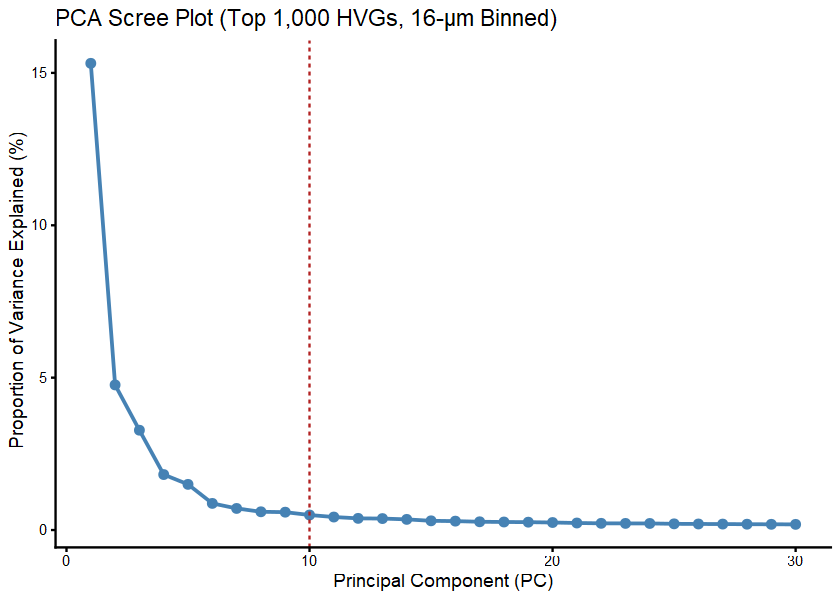

In [24]:
# Extract proportion of variance explained and generate scree diagnostic plot
percent_var <- attr(reducedDim(spe, "PCA"), "percentVar")

# Generate scree diagnostic plot
pca_scree_df <- data.frame(
  PC = seq_along(percent_var),
  VarianceExplained = percent_var,
  CumulativeVariance = cumsum(percent_var)
)

options(repr.plot.width = 7, repr.plot.height = 5)

ggplot(pca_scree_df, aes(x = PC, y = VarianceExplained)) +
  geom_point(color = "steelblue", size = 2) +
  geom_line(color = "steelblue", linewidth = 0.8) +
  geom_vline(xintercept = 10, linetype = "dashed", color = "firebrick") +
  theme_classic() +
  labs(
    title = "PCA Scree Plot (Top 1,000 HVGs, 16-µm Binned)",
    x = "Principal Component (PC)",
    y = "Proportion of Variance Explained (%)"
  )

While the scree trajectory preserves the same steep L-shaped decay observed in [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb), 16-µm binning noticeably concentrates variance into the leading axis: `PC1` rises from ≈ 9.4% in segmented cells to ≈ 15.3%, whereas `PC2` drops from ≈ 7.0% to ≈ 4.8%, reflecting the amplified stromal-versus-epithelial contrast of the ECM collagen drivers (`COL3A1`, `COL1A1`, `COL1A2`, `SPARC`) and reduced single-cell shot noise across 256 µm² squares. Following `PC3` (≈ 3.2%), a brief shelf appears across `PC4`–`PC5` (≈ 1.7% and ≈ 1.4%) before declining further through `PC6` (≈ 0.8%) and `PC7`–`PC8` (≈ 0.6%) into the asymptotic flat plateau (< 0.5% per component from `PC9`–`PC10` onward). Although the visual elbow arrives slightly earlier (≈ `PC6`–`PC8`) than in segmented space (`PC9`–`PC10`), retaining 10 principal components (`n_dimred` = 10) remains well-calibrated: truncation errors are asymmetric, as dropping `PC6`–`PC8` can erase subtle, low-abundance niches (vascular, muscularis mucosae, or crypt-base states), whereas retaining 1–2 near-plateau components adds negligible Euclidean distortion when components remain unscaled (`scale = FALSE`) and preserves direct methodological parity with the previous analysis on segmented data.

#### Spatial Projection & Gene Loadings

Because `Voyager::spatialReducedDim()` targets `SpatialFeatureExperiment` objects, we map `PCA_1`–`PCA_4` onto the 16-µm grid by temporarily attaching the top 4 components to `colData(spe)` and rendering them with `ggspavis::plotCoords()` using the same centered diverging `"roma"` palette (`scico::scale_color_scico(palette = "roma", direction = -1, midpoint = 0)`). We inspect whether major compartments—normal mucosa, invasive adenocarcinoma, desmoplastic stroma, and immune-rich lamina propria—remain cleanly resolved at 16-µm resolution.

In [25]:
pca_mat <- reducedDim(spe, "PCA")[, 1:4]
colnames(pca_mat) <- paste0("PCA_", 1:4)
for (pc_col in colnames(pca_mat)) {
  spe[[pc_col]] <- pca_mat[, pc_col]
}

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


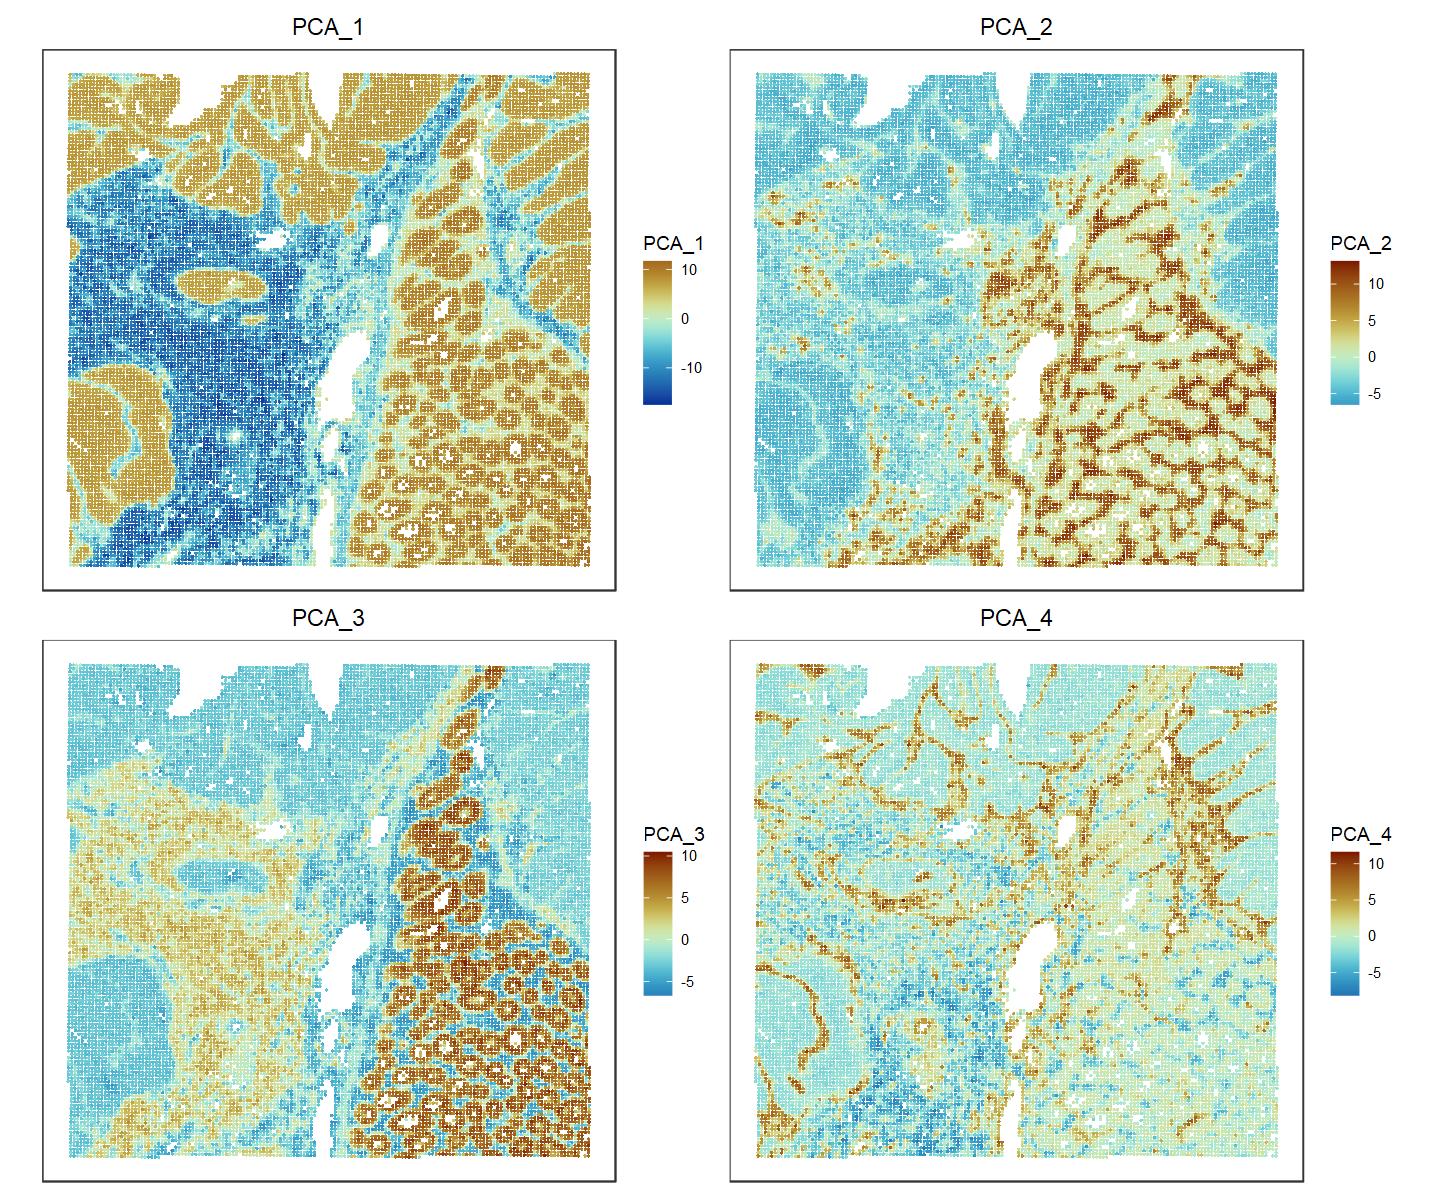

In [26]:
# Map top 4 standard PCs onto 16-µm bin coordinates using Voyager's diverging "roma" palette
options(repr.plot.width = 12, repr.plot.height = 10)

p_pca_spatial <- lapply(colnames(pca_mat), function(pc_col) {
  plotCoords(spe, annotate = pc_col, point_size = 0.35) +
    scico::scale_color_scico(
      palette = "roma",
      direction = -1,
      midpoint = 0,
      na.value = "gray",
      name = pc_col
    ) +
    labs(title = pc_col)
})

wrap_plots(p_pca_spatial, ncol = 2)

Even without spatial coordinates as inputs, the leading four unconstrained principal components recover sharp anatomical organization across the 16-µm lattice (note that `ggspavis::plotCoords()` reverses the Y-axis to match H&E orientation, placing normal mucosa in the lower-right, and PCA eigenvectors are defined only up to a ±1 sign flip relative to [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb)). **`PCA_1`** (≈ 15.3% variance) exhibits the cleanest stroma-versus-epithelium bifurcation: deep cyan/blue scores (down to −15) densely blanket the left-hand desmoplastic stroma and the diagonal muscularis mucosae ribbon, while positive brown/tan scores (+5 to +10) unite all epithelial territories—both the normal colonic crypts on the lower-right and the invasive and superficial adenocarcinoma glands on the upper and far-left margins. **`PCA_2`** (≈ 4.8% variance) shifts orthogonal to this axis to highlight mucosal humoral immunity, with brown scores (+5 to +10) tracing the inter-crypt lamina propria honeycomb on the right and focal peritumoral immune cuffs along the central cleft against cyan/blue epithelial and stromal backgrounds. **`PCA_3`** (≈ 3.2% variance) selectively accentuates the differentiated normal crypt rings in strong brown (+5 to +10) against cyan/blue upper-mucosa and invasive regions, whereas **`PCA_4`** (≈ 1.7% variance) captures finer microenvironmental streaks along glandular margins, muscularis interfaces, and submucosal vessels.

Compared with the single-cell projections in [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb), 16-µm binning visibly dampens cell-to-cell speckle within `PCA_1`–`PCA_3`, yielding smoother macro-compartment fields. Nevertheless, unconstrained PCA remains blind to spatial neighborhood context: because normal crypts and invasive tumor glands share core epithelial gene programs, `PCA_1` places both compartments at the same brown pole, leaving fine spatial domain separation to neighborhood-aware **BANKSY** dimensionality reduction.

#### Deconstructing Principal Component Loadings (`PC1` & `PC2`)

Inspecting the `rotation` matrix ($V$ in $Z = X V$) and projecting our 10 benchmark genes onto the `PC1 × PC2` plane reveals which gene modules define each pole of the embedding and how 256 µm² partial-volume mixing populates intermediate regions between tissue archetypes.

In [27]:
# List metadata attached to the reducedDim object
reducedDim(spe, "PCA") |> attributes() |> names()

[1] "dim"          "dimnames"     "varExplained" "percentVar"   "rotation"

In [28]:
# Extract gene rotation (loadings) matrix and top 10 drivers for PC1 and PC2
pca_rot <- attr(reducedDim(spe, "PCA"), "rotation")

lapply(c("PC1", "PC2"), function(pc) {
  pca_rot[, pc] |>
    abs() |>
    sort(decreasing = TRUE) |>
    names() |>
    head(n = 10)
}) |> setNames(c("PC1", "PC2"))

$PC1
 [1] "COL3A1"  "COL1A1"  "COL1A2"  "SPARC"   "VIM"     "MMP2"    "TAGLN"  
 [8] "MUC12"   "CEACAM5" "LUM"    

$PC2
 [1] "IGKC"    "IGHG1"   "JCHAIN"  "CEACAM6" "IGHM"    "PIGR"    "FTH1"   
 [8] "PYGB"    "IGHA1"   "CEACAM5"

Comparing these top loadings with [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb) explains why `PC1` gained variance while `PC2` shifted its counter-pole. **`PC1`** retains 9 of the 10 segmented drivers—commanded by stromal ECM and myofibroblast genes (`COL3A1`, `COL1A1`, `COL1A2`, `SPARC`, `VIM`, `MMP2`, `TAGLN`) paired against epithelial `MUC12` and `CEACAM5`—while `IGKC` drops out of the top 10 in favor of stromal `LUM`, purifying `PC1` into a cleaner stroma-versus-epithelium axis. **`PC2`** remains anchored by the exact same five humoral immunoglobulin genes (`IGKC`, `IGHG1`, `JCHAIN`, `IGHM`, `IGHA1`), but instead of opposing collagens as in segmented single cells, those plasma-cell drivers now balance against epithelial and crypt markers (`CEACAM6`, `PIGR`, `PYGB`, `CEACAM5`).

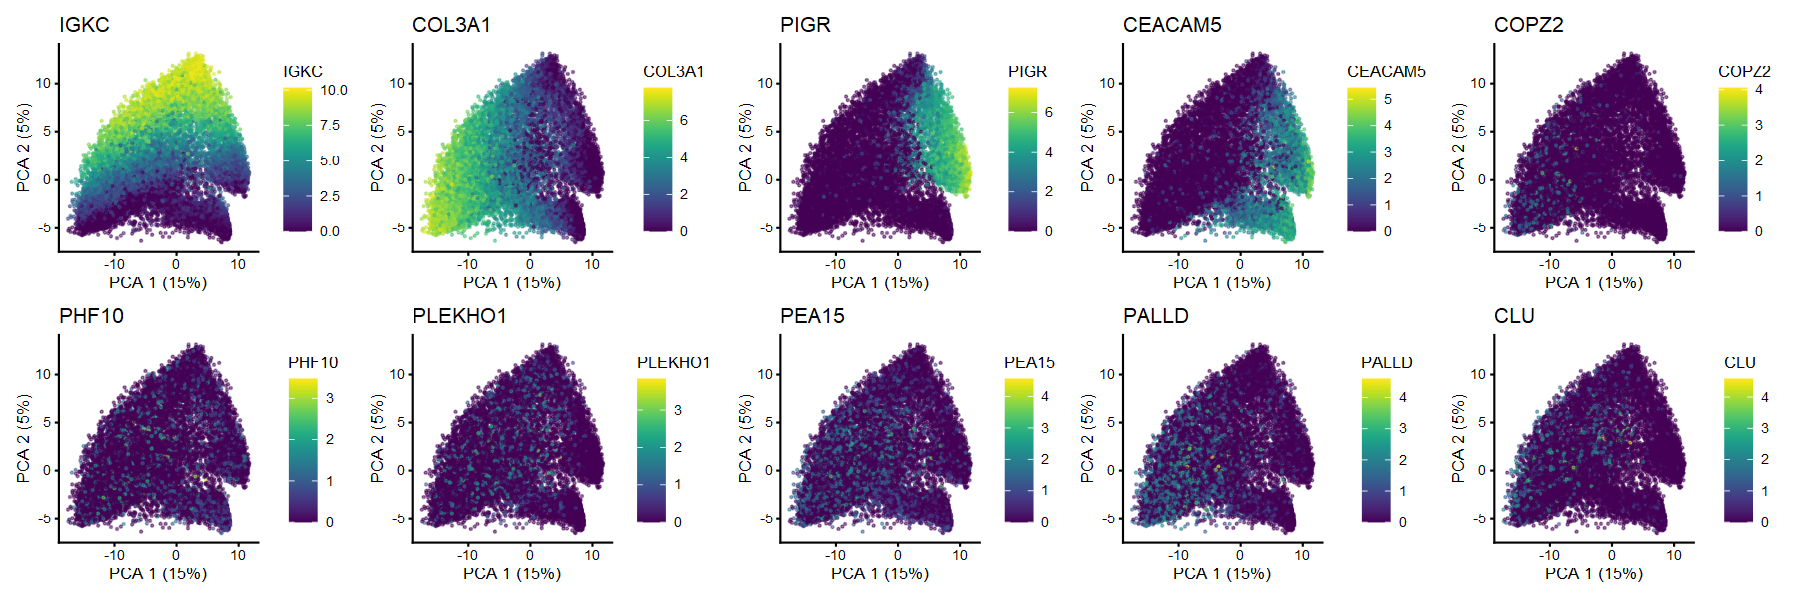

In [29]:
# Project the 10 benchmark genes onto the 2D PC1 x PC2 embedding
pca_plots <- lapply(svg_benchmark_genes, function(gene) {
  plotReducedDim(
    spe, 
    dimred = "PCA", 
    colour_by = gene, 
    point_size = 0.25, 
    point_alpha = 0.5 
  ) +
    labs(title = gene, color = NULL) +
    theme_classic(base_size = 10)
})

options(repr.plot.width = 15, repr.plot.height = 5)
wrap_plots(pca_plots, ncol = 5)

Projecting our 10 benchmark genes onto the `PCA 1` (≈ 15%) × `PCA 2` (≈ 5%) plane confirms that the 21,278 bins organize into the same **triangular 2-simplex** observed in segmented single cells (with `PCA 1` mirrored horizontally relative to [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb)). Each vertex corresponds to one of the tissue's three foundational archetypes: humoral plasma cells (`IGKC`) crown the **top apex** (`PCA_1` ≈ 0, `PCA_2` ≈ +11), desmoplastic CAF and ECM stroma (`COL3A1`) occupy the **bottom-left vertex** (`PCA_1` ≈ −15, `PCA_2` ≈ −5), and epithelial compartments (`PIGR` and `CEACAM5`) form the **right-hand wing** (`PCA_1` ≈ +10).

Notice that partial-volume mixing across 256 µm² boundary bins populates the triangle's interior continuously as convex combinations of those three poles, while the subtle vertical split along the right edge separates `PIGR`-high normal crypts (shifted upward toward `IGKC`-rich lamina propria) from `CEACAM5`-high invasive tumor glands (extending into the `IGKC`-poor bottom-right tip). Among our sampled HVGs, `PALLD` concentrates selectively in the bottom-left `COL3A1`+ stromal wing and `CLU` shows weak stromal/central enrichment, whereas diffuse `PHF10`, `PEA15`, `COPZ2`, and `PLEKHO1` speckle across the entire simplex without anchoring to any single archetype.

### Spatially-Aware Dimensionality Reduction (BANKSY)

#### Neighborhood Feature Augmentation

We next apply BANKSY (`k_geom = 20`, `lambda = 0.8`) to the 1,000-HVG `SpatialExperiment` slice (`spe[rowData(spe)[["is_hvg"]], ]`). `Banksy::computeBanksy()` supports `SpatialExperiment` and `DelayedMatrix` directly using `coord_names = spatialCoordsNames(spe)`.

In [30]:
# Define BANKSY parameters matching Notebook 10 for direct architectural comparison
k_geom <- 20
lambda_weight <- 0.8
xy_coords <- spatialCoordsNames(spe)

# Compute BANKSY neighborhood aggregates on the 1,000-HVG slice
set.seed(42)
spe_banksy <- computeBanksy(
  spe[rowData(spe)[["is_hvg"]], ],
  assay_name = "logcounts",
  coord_names = xy_coords,
  k_geom = k_geom
)

Computing neighbors...

Spatial mode is kNN_median

Parameters: k_geom=20

Done

Done



In [31]:
# Compute 10 spatio-molecular PCs
set.seed(42)
spe_banksy <- runBanksyPCA(
  spe_banksy,
  lambda = lambda_weight,
  npcs = 10
)

# Transfer BANKSY PCs into primary spe container and release temporary object
banksy_slot <- grep("^PCA_", reducedDimNames(spe_banksy), value = TRUE)[1]
reducedDim(spe, "PCA_banksy") <- reducedDim(spe_banksy, banksy_slot)
rm(spe_banksy)

In [32]:
# Verify all stored dimensionality reduction slots
reducedDimNames(spe)

[1] "PCA"        "PCA_banksy"

#### Spatial Projection & Comparison with Standard PCA

We map the top four BANKSY spatial principal components onto the 16-µm bin grid to verify how neighborhood augmentation separates macro-anatomical compartments (such as normal colonic mucosa vs. invasive adenocarcinoma and reactive submucosa) along leading components.

In [33]:
banksy_mat <- reducedDim(spe, "PCA_banksy")[, 1:4]
colnames(banksy_mat) <- paste0("PCA_banksy_", 1:4)
for (pc_col in colnames(banksy_mat)) {
  spe[[pc_col]] <- banksy_mat[, pc_col]
}

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


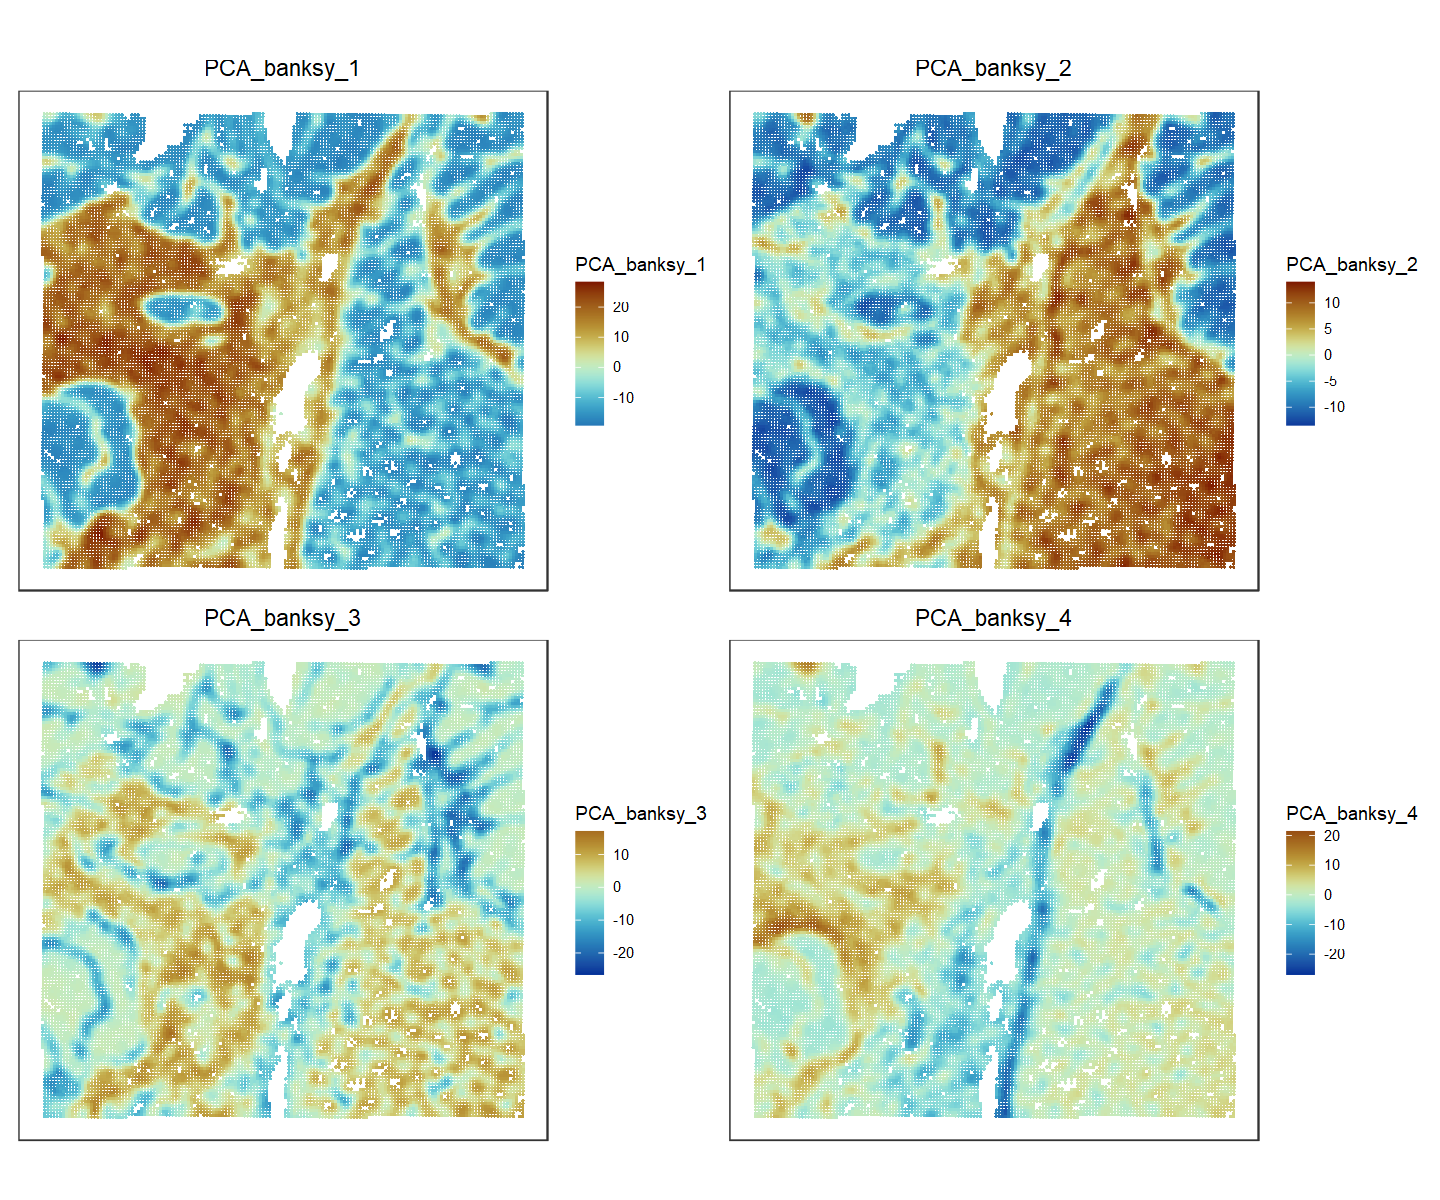

In [34]:
# Map top 4 BANKSY spatial PCs onto 16-µm bin coordinates
options(repr.plot.width = 12, repr.plot.height = 10)

p_banksy_spatial <- lapply(colnames(banksy_mat), function(pc_col) {
  plotCoords(spe, annotate = pc_col, point_size = 0.35) +
    scico::scale_color_scico(
      palette = "roma",
      direction = -1,
      midpoint = 0,
      na.value = "gray",
      name = pc_col
    ) +
    labs(title = pc_col)
})

wrap_plots(p_banksy_spatial, ncol = 2)

Projecting `PCA_banksy_1`–`PCA_banksy_4` onto the 16-µm lattice confirms both the domain-denoising strength of binned BANKSY and the preservation of our key SVGs. Across all four components, neighborhood aggregation (`k_geom` = 20, `lambda` = 0.8) eliminates residual bin-to-bin speckle, transforming the tissue into smooth, contiguous anatomical fields. Because ECM variance dominates 16-µm binned space, **`PCA_banksy_1`** retains the primary stroma-versus-epithelium axis—delineating the `COL3A1`+ desmoplastic stroma in rich brown (+10 to +25) against epithelial glands in cyan/blue (−10)—while **`PCA_banksy_2`** resolves the exact biological ambiguity that defeated unconstrained PCA: the entire normal colonic mucosa on the lower-right (uniting `PIGR`+ crypts and `IGKC`+ lamina propria) coalesces into a single warm brown domain (+5 to +15), cleanly bifurcated from the invasive adenocarcinoma nests and left-hand tumor bed in deep blue (−5 to −10).

Crucially, pairing 256 µm² grid depth with isotropic lattice neighbors does not wash out narrow histological structures in higher components. **`PCA_banksy_3`** resolves finer regional gradients across mucosal folds and submucosal pockets, and **`PCA_banksy_4`** isolates the diagonal **muscularis mucosae** (`TAGLN`, `PALLD`, `CLU`) as a razor-sharp deep blue ribbon (−15 to −25) dividing the mucosa from the submucosa, balanced against a warm brown stromal band along the lower-left tumor margin—establishing a clean, multi-scale foundation for eigenvalue diagnostics and UMAP manifold projection.

> **Why 16-µm Binned Lattices Excel at BANKSY Domain Discovery:** Keeping `k_geom` = 20 and `lambda` = 0.8 matches [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb) for direct cross-architecture comparison while leveraging two _structural strengths of binned grids_. First, higher per-bin UMI capture across 256 µm² squares lowers zero-inflation before spatial aggregation even begins, giving BANKSY a cleaner intrinsic signal ($\mathbf{x}_i$). Second, on a regular square lattice, `k_geom` = 20 samples an isotropic ≈ 2–2.5-bin radius (≈ 32–40 µm) uniformly across both dense epithelium and sparse stroma—avoiding the uneven neighbor jumps of variable-density cell graphs and yielding sharp, contiguous macro-anatomical domains at lower computational cost (21,278 bins vs. 33,709 cells). When an analysis prioritizes finer sub-40 µm structures such as individual capillaries or focal immune cuffs, simply dialing down neighborhood mixing (`lambda` ≈ 0.2–0.5 or `k_geom` = 8 Queen contiguity) preserves crisp local contrast while still benefiting from the deeper per-bin transcriptome.

#### Eigenvalue Scree Diagnostics (`PCA_banksy`)

To quantify how steeply spatial variance concentrates in `PC1` relative to `PC2`–`PC10`, we inspect the eigenspectrum of `PCA_banksy`. Because `Banksy::runBanksyPCA(..., npcs = 10)` omits a `percentVar` attribute—computing only the top 10 eigenvectors of the 2,000-feature augmented matrix (1,000 intrinsic HVGs plus 1,000 neighbor-averaged HVGs; [see the course notes](../assets/notes/06-intermediate_processing.md))—we plot raw component variances directly from `reducedDim(spe, "PCA_banksy")`.

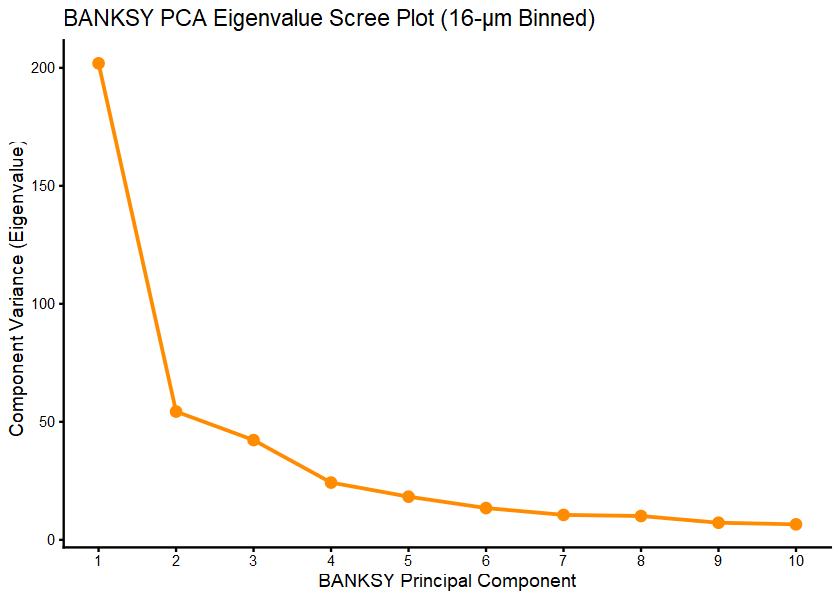

In [35]:
# Compute component variance (eigenvalue) for each of the 10 BANKSY PCs
banksy_var <- apply(reducedDim(spe, "PCA_banksy"), 2, var)

banksy_scree_df <- data.frame(
  PC = seq_along(banksy_var),
  Variance = banksy_var
)

options(repr.plot.width = 7, repr.plot.height = 5)

ggplot(banksy_scree_df, aes(x = PC, y = Variance)) +
  geom_point(color = "darkorange", size = 2.5) +
  geom_line(color = "darkorange", linewidth = 0.8) +
  scale_x_continuous(breaks = 1:10) +
  theme_classic() +
  labs(
    title = "BANKSY PCA Eigenvalue Scree Plot (16-µm Binned)",
    x = "BANKSY Principal Component",
    y = "Component Variance (Eigenvalue)"
  )

`PC1` absorbs by far the largest eigenvalue (≈ 202), reflecting the tissue-wide ECM stroma-versus-epithelium axis, before dropping nearly four-fold to `PC2` (≈ 54) and `PC3` (≈ 43). Crucially, even though eigenvalues taper progressively through `PC4` (≈ 25) and `PC5` (≈ 18) toward a gentle tail across `PC6`–`PC10` (≈ 7–13), components with substantially smaller eigenvalues still encode sharp anatomical domains—as demonstrated by `PCA_banksy_2` (normal mucosa vs. invasive tumor) and `PCA_banksy_4` (the muscularis mucosae)—making joint 10-component visualization via UMAP an informative diagnostic complement.

### Non-Linear Manifold Visualization (UMAP)

Finally, we project both the top 10 unconstrained PCs (`UMAP`) and the 10 BANKSY spatial PCs (`UMAP_banksy`) into 2D manifolds using `scater::runUMAP()`, coloring bins by `detected` gene complexity on a `log10` scale to compare how effectively spatial augmentation resolves discrete histological domains in binned space.

In [36]:
# Compute UMAP on top 10 standard PCs
set.seed(42)
spe <- runUMAP(
  spe, 
  dimred = "PCA", 
  n_dimred = 10, 
  name = "UMAP"
)

In [37]:
# Compute UMAP on 10 BANKSY spatial PCs
set.seed(42)
spe <- runUMAP(
  spe, 
  dimred = "PCA_banksy", 
  name = "UMAP_banksy"
)

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


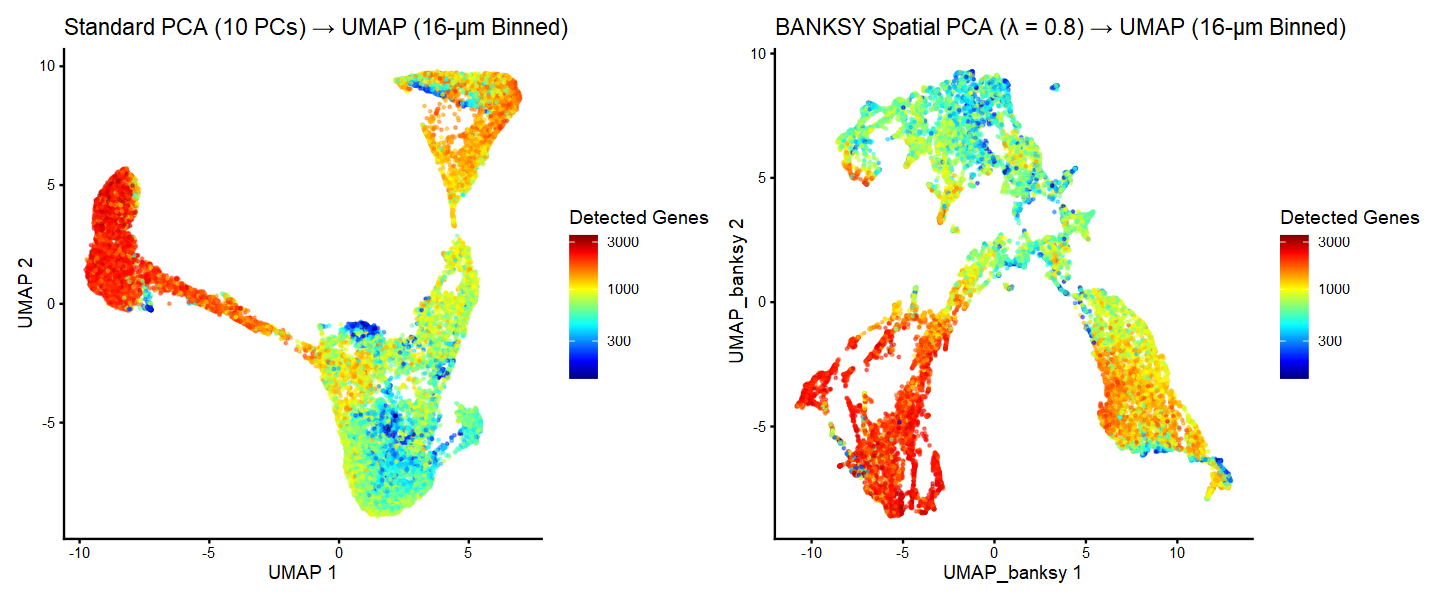

In [38]:
# Side-by-side comparison of Standard UMAP vs. BANKSY UMAP
options(repr.plot.width = 12, repr.plot.height = 5)

p_umap_std <- plotReducedDim(
  spe, 
  dimred = "UMAP", 
  colour_by = "detected", 
  point_size = 0.3, 
  point_alpha = 0.5
) +
  scale_color_gradientn(colors = pals::jet(), trans = "log10") +
  labs(title = "Standard PCA (10 PCs) → UMAP (16-µm Binned)", color = "Detected Genes") +
  theme_classic()

p_umap_banksy <- plotReducedDim(
  spe, 
  dimred = "UMAP_banksy", 
  colour_by = "detected", 
  point_size = 0.3, 
  point_alpha = 0.5
) +
  scale_color_gradientn(colors = pals::jet(), trans = "log10") +
  labs(title = "BANKSY Spatial PCA (λ = 0.8) → UMAP (16-µm Binned)", color = "Detected Genes") +
  theme_classic()

p_umap_std + p_umap_banksy

Both UMAP manifolds clearly reflect the transition from discrete single-cell polygons to a continuous 16-µm capture grid. In the non-spatial embedding (`Standard PCA → UMAP`, left panel), whereas segmented cells in [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb) snapped into two disconnected components, the 16-µm bins organize into three lobes—two high-complexity lobes (left in deep red and top-right in orange, ≈ 1,000–3,000+ detected genes) and a lower-complexity stromal and immune body (bottom in blue/cyan/green, ≈ 200–1,000 genes)—linked together by narrow, continuous bridges. Those bridging filaments are populated by partial-volume boundary bins straddling epithelial–stromal and crypt–lamina propria interfaces, which supply intermediate transcriptomic mixtures that keep the $k$-nearest-neighbor graph connected across lineages.

Synthesizing all 10 BANKSY components (`BANKSY Spatial PCA → UMAP`, right panel) reorganizes the manifold into a crisp **three-armed ("trimer") architecture** converging only along narrow central transition necks. Compounding 256 µm² bin depth with isotropic `k_geom` = 20 neighborhood averaging (`lambda` = 0.8) drives high intra-compartment homogeneity, cleanly projecting the two transcriptionally active epithelial/mucosal domains into diverging lower arms (bottom-left deep-red arm at ≈ 1,500–3,000+ genes and bottom-right orange-yellow arm at ≈ 800–2,000 genes) while isolating the lower-complexity stromal and submucosal compartment in the upper cyan/blue/green arm (≈ 200–1,000 genes). Consistent with the size-factor compartments established in [notebook 08](./08-normalization_VisiumHD_binned.ipynb), `detected` gene counts vary smoothly across biological compartments without fracturing into low-count technical debris clusters, providing a well-structured latent space for downstream spatial domain clustering.

> **Do We Strictly Need UMAP on 16-µm Binned Data?** Downstream spatial clustering operates directly on the 10-dimensional `PCA` and `PCA_banksy` embeddings rather than 2D UMAP coordinates, and spatial transcriptomics already provides the undistorted physical `(x, y)` tissue canvas where `PCA_banksy_1`–`PCA_banksy_4` resolve both macro-domains and thin structures such as the muscularis mucosae. Moreover, because partial-volume interface bins bridge adjacent compartments in $k$-NN space, 16-µm UMAPs appear more connected than single-cell embeddings. Even so, retaining `UMAP_banksy` remains worthwhile as a compact 10-PC diagnostic check—confirming that technical gene complexity (`detected`) forms smooth biological gradients rather than artifact islands and providing a complementary manifold view for overlaying spatial cluster labels in the next module.

## Finalization

Before saving, we remove the temporary `PCA_1..4` and `PCA_banksy_1..4` plotting columns from `colData(spe)` (keeping the full embeddings cleanly inside `reducedDim(spe)`) and serialize the enriched `SpatialExperiment` object and its HDF5-backed assays via `HDF5Array::saveHDF5SummarizedExperiment()`.

In [39]:
# Clean up temporary colData plotting columns while preserving reducedDim slots
temp_pc_cols <- grep("^(PCA|PCA_banksy)_[1-4]$", colnames(colData(spe)), value = TRUE)
colData(spe)[, temp_pc_cols] <- NULL

# Inspect final object structure
spe

class: SpatialExperiment 
dim: 18027 21278 
metadata(2): resouces spatialList
assays(2): counts logcounts
rownames(18027): SAMD11 NOC2L ... MT-ND6 MT-CYB
rowData names(10): ID Symbol ... prop_sv padj
colnames(21278): s_016um_00144_00175-1 s_016um_00204_00145-1 ...
  s_016um_00231_00291-1 s_016um_00193_00227-1
colData names(35): barcode in_tissue ... CEACAM5_raw CEACAM5_lognorm
reducedDimNames(4): PCA PCA_banksy UMAP UMAP_banksy
mainExpName: Gene Expression
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

In [40]:
# Save enriched SpatialExperiment object to disk
output_dir <- "output/spe_visiumhd_binned_dimred"
if (dir.exists(output_dir)) {
  unlink(output_dir, recursive = TRUE)
}

saveHDF5SummarizedExperiment(
  x = spe, 
  dir = output_dir, 
  replace = TRUE
)

list.files(output_dir, full.names = TRUE)

[1] "output/spe_visiumhd_binned_dimred/assays.h5"
[2] "output/spe_visiumhd_binned_dimred/se.rds"

We clear the workspace and trigger garbage collection to release intermediate dimensionality-reduction embeddings and count matrices from memory before opening the next module.

In [41]:
rm(list = ls())
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,10041556,536.3,16410508,876.5,16410508,876.5
Vcells,20870291,159.3,90442292,690.1,201819513,1539.8
